In [2]:
# https://skymind.ai/wiki/generative-adversarial-network-gan
import keras
import numpy as np
import matplotlib.pyplot as plt

from keras.datasets import mnist
from keras.optimizers import Adam # use legacy to avoid error
from keras.models import Sequential
from keras.layers import Flatten
from keras.layers import Dense
from keras.layers import LeakyReLU
from keras.layers import Input
from keras.layers import BatchNormalization
from keras.layers import Reshape
from keras.models import Model

In [3]:
# pip install print_versions
from print_versions import print_versions
print_versions(globals())

keras==3.11.3
numpy==2.3.3


In [13]:
class GAN():
    def __init__(self):
        self.img_rows = 28
        self.img_cols = 28
        self.channels = 1
        self.img_shape = (self.img_rows, self.img_cols, self.channels)
        self.latent_dim = 100

        optimizer = Adam(0.0002, 0.5)

        # Build and compile the discriminator
        self.discriminator = self.build_discriminator()
        self.discriminator.compile(loss='binary_crossentropy',
            optimizer=optimizer,
            metrics=['accuracy'])

        # Build and compile the generator
        self.generator = self.build_generator()
        self.generator.compile(loss='binary_crossentropy', optimizer=optimizer)

        # The generator takes noise as input and generated imgs
        z = Input(shape=(100,))
        img = self.generator(z)

        # For the combined model we will only train the generator
        self.discriminator.trainable = False

        # The valid takes generated images as input and determines validity
        valid = self.discriminator(img)

        # The combined model  (stacked generator and discriminator) takes
        # noise as input => generates images => determines validity
        self.combined = Model(z, valid)
        self.combined.compile(loss='binary_crossentropy', optimizer=optimizer)

    def build_generator(self):

        noise_shape = (100,)

        model = Sequential()

        model.add(Dense(256, input_shape=noise_shape))
        model.add(LeakyReLU(alpha=0.2))
        model.add(BatchNormalization(momentum=0.8))
        model.add(Dense(512))
        model.add(LeakyReLU(alpha=0.2))
        model.add(BatchNormalization(momentum=0.8))
        model.add(Dense(1024))
        model.add(LeakyReLU(alpha=0.2))
        model.add(BatchNormalization(momentum=0.8))
        model.add(Dense(np.prod(self.img_shape), activation='tanh'))
        model.add(Reshape(self.img_shape))

        model.summary()

        noise = Input(shape=noise_shape)
        img = model(noise)

        return Model(noise, img)

    def build_discriminator(self):

        img_shape = (self.img_rows, self.img_cols, self.channels)

        model = Sequential()

        model.add(Flatten(input_shape=img_shape))
        model.add(Dense(512))
        model.add(LeakyReLU(alpha=0.2))
        model.add(Dense(256))
        model.add(LeakyReLU(alpha=0.2))
        model.add(Dense(1, activation='sigmoid'))
        model.summary()

        img = Input(shape=img_shape)
        validity = model(img)

        return Model(img, validity)

    def train(self, epochs, batch_size=128, save_interval=50):

        # Load the dataset
        (X_train, _), (_, _) = mnist.load_data()

        # Rescale -1 to 1
        X_train = (X_train.astype(np.float32) - 127.5) / 127.5
        X_train = np.expand_dims(X_train, axis=3)

        half_batch = int(batch_size / 2)

        for epoch in range(epochs):

            # ---------------------
            #  Train Discriminator
            # ---------------------

            # Select a random half batch of images
            idx = np.random.randint(0, X_train.shape[0], half_batch)
            imgs = X_train[idx]

            noise = np.random.normal(0, 1, (half_batch, 100))

            # Generate a half batch of new images
            gen_imgs = self.generator.predict(noise)

            # Train the discriminator
            d_loss_real = self.discriminator.train_on_batch(imgs, np.ones((half_batch, 1)))
            d_loss_fake = self.discriminator.train_on_batch(gen_imgs, np.zeros((half_batch, 1)))
            d_loss = 0.5 * np.add(d_loss_real, d_loss_fake)


            # ---------------------
            #  Train Generator
            # ---------------------

            noise = np.random.normal(0, 1, (batch_size, 100))

            # The generator wants the discriminator to label the generated samples
            # as valid (ones)
            valid_y = np.array([1] * batch_size)

            # Train the generator
            g_loss = self.combined.train_on_batch(noise, valid_y)

            # Plot the progress
            print ("%d [D loss: %f, acc.: %.2f%%] [G loss: %f]" % (epoch, d_loss[0], 100*d_loss[1], g_loss))

            # If at save interval => save generated image samples
            if epoch % save_interval == 0:
                self.save_imgs(epoch)

    def save_imgs(self, epoch):
        r, c = 5, 5
        noise = np.random.normal(0, 1, (r * c, 100))
        gen_imgs = self.generator.predict(noise)

        # Rescale images 0 - 1
        gen_imgs = 0.5 * gen_imgs + 0.5

        fig, axs = plt.subplots(r, c)
        cnt = 0
        for i in range(r):
            for j in range(c):
                axs[i,j].imshow(gen_imgs[cnt, :,:,0], cmap='gray')
                axs[i,j].axis('off')
                cnt += 1
        fig.savefig("./images/mnist_%d.png" % epoch)
        plt.close()

In [14]:
if __name__ == '__main__':
    gan = GAN()
    gan.train(epochs=10000, batch_size=32, save_interval=200) #epoch 30,000

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_28 (Dense)                     │ (None, 512)                 │         401,920 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_20 (LeakyReLU)           │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_29 (Dense)                     │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_21 (LeakyReLU)           │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_30 (Dense)                     │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

...

1/1 [==============================] - 0s 48ms/step
644 [D loss: 0.655869, acc.: 59.38%] [G loss: 0.717183]
1/1 [==============================] - 0s 64ms/step
645 [D loss: 0.656699, acc.: 65.62%] [G loss: 0.725469]
1/1 [==============================] - 0s 64ms/step
646 [D loss: 0.680867, acc.: 56.25%] [G loss: 0.715935]
1/1 [==============================] - 0s 63ms/step
647 [D loss: 0.690729, acc.: 56.25%] [G loss: 0.722312]
1/1 [==============================] - 0s 51ms/step
648 [D loss: 0.647117, acc.: 62.50%] [G loss: 0.731734]
1/1 [==============================] - 0s 48ms/step
649 [D loss: 0.642915, acc.: 68.75%] [G loss: 0.720988]
1/1 [==============================] - 0s 79ms/step
650 [D loss: 0.661682, acc.: 50.00%] [G loss: 0.687727]
1/1 [==============================] - 0s 43ms/step
651 [D loss: 0.644916, acc.: 62.50%] [G loss: 0.716967]
1/1 [==============================] - 0s 54ms/step
652 [D loss: 0.670752, acc.: 53.12%] [G loss: 0.716201]
1/1 [=======================

1/1 [==============================] - 0s 47ms/step
720 [D loss: 0.625998, acc.: 75.00%] [G loss: 0.727149]
1/1 [==============================] - 0s 46ms/step
721 [D loss: 0.632260, acc.: 62.50%] [G loss: 0.711364]
1/1 [==============================] - 0s 61ms/step
722 [D loss: 0.674955, acc.: 71.88%] [G loss: 0.728505]
1/1 [==============================] - 0s 80ms/step
723 [D loss: 0.657268, acc.: 65.62%] [G loss: 0.712658]
1/1 [==============================] - 0s 47ms/step
724 [D loss: 0.649544, acc.: 56.25%] [G loss: 0.686029]
1/1 [==============================] - 0s 48ms/step
725 [D loss: 0.609167, acc.: 62.50%] [G loss: 0.682621]
1/1 [==============================] - 0s 42ms/step
726 [D loss: 0.663199, acc.: 56.25%] [G loss: 0.691673]
1/1 [==============================] - 0s 48ms/step
727 [D loss: 0.672295, acc.: 53.12%] [G loss: 0.708388]
1/1 [==============================] - 0s 47ms/step
728 [D loss: 0.615870, acc.: 68.75%] [G loss: 0.723382]
1/1 [=======================

1/1 [==============================] - 0s 47ms/step
796 [D loss: 0.675775, acc.: 50.00%] [G loss: 0.791704]
1/1 [==============================] - 0s 42ms/step
797 [D loss: 0.643205, acc.: 75.00%] [G loss: 0.769045]
1/1 [==============================] - 0s 64ms/step
798 [D loss: 0.692998, acc.: 46.88%] [G loss: 0.746829]
1/1 [==============================] - 0s 64ms/step
799 [D loss: 0.703059, acc.: 46.88%] [G loss: 0.732704]
1/1 [==============================] - 0s 47ms/step
800 [D loss: 0.655448, acc.: 62.50%] [G loss: 0.762347]
1/1 [==============================] - 0s 53ms/step
801 [D loss: 0.628573, acc.: 71.88%] [G loss: 0.755898]
1/1 [==============================] - 0s 64ms/step
802 [D loss: 0.685297, acc.: 50.00%] [G loss: 0.755055]
1/1 [==============================] - 0s 51ms/step
803 [D loss: 0.649260, acc.: 56.25%] [G loss: 0.798993]
1/1 [==============================] - 0s 64ms/step
804 [D loss: 0.671400, acc.: 59.38%] [G loss: 0.786453]
1/1 [=======================

1/1 [==============================] - 0s 42ms/step
871 [D loss: 0.632057, acc.: 68.75%] [G loss: 0.750927]
1/1 [==============================] - 0s 54ms/step
872 [D loss: 0.619939, acc.: 75.00%] [G loss: 0.747733]
1/1 [==============================] - 0s 54ms/step
873 [D loss: 0.631775, acc.: 65.62%] [G loss: 0.739070]
1/1 [==============================] - 0s 64ms/step
874 [D loss: 0.605216, acc.: 71.88%] [G loss: 0.752584]
1/1 [==============================] - 0s 47ms/step
875 [D loss: 0.649257, acc.: 71.88%] [G loss: 0.762455]
1/1 [==============================] - 0s 45ms/step
876 [D loss: 0.660058, acc.: 59.38%] [G loss: 0.750688]
1/1 [==============================] - 0s 45ms/step
877 [D loss: 0.637843, acc.: 68.75%] [G loss: 0.729138]
1/1 [==============================] - 0s 48ms/step
878 [D loss: 0.629221, acc.: 62.50%] [G loss: 0.721627]
1/1 [==============================] - 0s 48ms/step
879 [D loss: 0.639666, acc.: 59.38%] [G loss: 0.723345]
1/1 [=======================

1/1 [==============================] - 0s 64ms/step
947 [D loss: 0.657186, acc.: 59.38%] [G loss: 0.836098]
1/1 [==============================] - 0s 63ms/step
948 [D loss: 0.649095, acc.: 65.62%] [G loss: 0.848781]
1/1 [==============================] - 0s 79ms/step
949 [D loss: 0.653223, acc.: 68.75%] [G loss: 0.776134]
1/1 [==============================] - 0s 45ms/step
950 [D loss: 0.668306, acc.: 56.25%] [G loss: 0.759839]
1/1 [==============================] - 0s 49ms/step
951 [D loss: 0.677040, acc.: 56.25%] [G loss: 0.753574]
1/1 [==============================] - 0s 48ms/step
952 [D loss: 0.653754, acc.: 59.38%] [G loss: 0.793936]
1/1 [==============================] - 0s 48ms/step
953 [D loss: 0.619416, acc.: 68.75%] [G loss: 0.819841]
1/1 [==============================] - 0s 47ms/step
954 [D loss: 0.639851, acc.: 65.62%] [G loss: 0.815491]
1/1 [==============================] - 0s 63ms/step
955 [D loss: 0.671862, acc.: 43.75%] [G loss: 0.765937]
1/1 [=======================

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

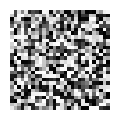

In [31]:
noise = np.random.normal(0, 1, (1, 100))
gen_img = gan.generator.predict(noise)

# Rescale images 0 - 1
# gen_img = gen_img[0,:,:,0]
gen_img = np.squeeze(gen_img)
gen_img = 0.5 * gen_img + 0.5

# Set the figure size to exactly 1x1 inch
fig = plt.figure(figsize=(1, 1))

# Add an axes layout that fills 100% of the figure canvas
ax = fig.add_axes([0, 0, 1, 1])

# Display the image array
ax.imshow(gen_img, cmap='gray')
ax.axis('off')

# plt.imshow(, cmap='gray')